# COVID-19 Data Analysis and Visualisation
**HCLTech Career Shaper Programme | Project No. 48 | Domain: Data Analytics / Python**

| Field | Details |
|---|---|
| Learner | Yash Verma (Roll No. 2300320130290) |
| College | ABES EC |
| Mentor | Dipali Kedar Patki |
| Submission | 31 October 2026 |

**Data source:** Our World in Data (OWID) COVID-19 dataset, licensed CC BY 4.0 - https://github.com/owid/covid-19-data.
OWID compiles official figures reported to the WHO and national health authorities. All figures here are *reported* figures; true infections and deaths were higher in many countries because of limited testing.

**Notebook outline**
1. Setup
2. Audit of the dataset.csv supplied with the brief
3. Load and check the cleaned dataset
4. Feature engineering (daily values, per-million rates, case fatality rate, vaccination coverage)
5. Global overview and pandemic waves
6. Country and continent comparison
7. Vaccination analysis
8. Case study: India
9. Correlation analysis
10. Data-quality flags (anomalies)
11. Key findings

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 120)

ROOT = Path("..")
DATA = ROOT / "data"
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

# Fixed colour per continent (same colour for the same continent in every chart)
CONTINENT_COLORS = {"Africa": "#2a78d6", "Asia": "#eb6834", "Europe": "#1baf7a",
                    "North America": "#eda100", "Oceania": "#e87ba4", "South America": "#008300"}
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ae",
                     "axes.titleweight": "bold", "axes.titlesize": 12})

def save(fig, name):
    fig.savefig(IMG / name)
    plt.show()

millions = mtick.FuncFormatter(lambda v, _: f"{v/1e6:,.0f}M" if abs(v) >= 1e6 else f"{v/1e3:,.0f}K")

## 2. Audit of the dataset.csv supplied with the brief
The brief supplied a 500-row `dataset.csv` (10 countries x 50 days, Jan-Feb 2024). Before using it, its values were checked for internal consistency.

In [2]:
orig = pd.read_csv(DATA / "dataset_original.csv")
print("Shape:", orig.shape)
print("Missing values:", orig.isna().sum().sum(), "| Duplicate rows:", orig.duplicated().sum())
orig.head()

Shape: (500, 8)
Missing values: 0 | Duplicate rows: 0


,date,country,confirmed,deaths,recovered,vaccinated,population,continent
0,2024-01-01,India,1408738,33164,2919201,658769468,330000000,Oceania
1,2024-01-01,USA,1128067,67534,2793134,400733312,215000000,Asia
2,2024-01-01,Brazil,3119576,6830,2074496,388650343,67000000,Asia
3,2024-01-01,UK,1050578,1811,1196353,780309519,67000000,Africa
4,2024-01-01,Germany,4546989,49983,1637395,834250405,215000000,Oceania


In [3]:
s = orig.sort_values("date")
audit = pd.DataFrame({
    "Check": [
        "Countries with more than one population value",
        "Countries assigned to more than one continent",
        "Rows where vaccinated > population",
        "Rows where deaths > confirmed",
        "Rows where recovered > confirmed",
        "Countries whose cumulative 'confirmed' ever falls",
    ],
    "Result": [
        f"{(orig.groupby('country')['population'].nunique() > 1).sum()} of {orig['country'].nunique()}",
        f"{(orig.groupby('country')['continent'].nunique() > 1).sum()} of {orig['country'].nunique()}",
        f"{(orig['vaccinated'] > orig['population']).sum()} of {len(orig)} ({(orig['vaccinated'] > orig['population']).mean():.0%})",
        f"{(orig['deaths'] > orig['confirmed']).sum()} of {len(orig)}",
        f"{(orig['recovered'] > orig['confirmed']).sum()} of {len(orig)} ({(orig['recovered'] > orig['confirmed']).mean():.0%})",
        f"{(~s.groupby('country')['confirmed'].apply(lambda x: x.is_monotonic_increasing)).sum()} of {orig['country'].nunique()}",
    ]})
audit

,Check,Result
0,Countries with more than one population value,10 of 10
1,Countries assigned to more than one continent,10 of 10
2,Rows where vaccinated > population,342 of 500 (68%)
3,Rows where deaths > confirmed,9 of 500
4,Rows where recovered > confirmed,228 of 500 (46%)
5,Countries whose cumulative 'confirmed' ever falls,10 of 10


In [4]:
# Example: the same country carries five different populations and continents
orig[orig["country"] == "India"][["date", "country", "population", "continent"]].head(5)

,date,country,population,continent
0,2024-01-01,India,330000000,Oceania
10,2024-01-02,India,1400000000,Asia
20,2024-01-03,India,83000000,Americas
30,2024-01-04,India,83000000,Americas
40,2024-01-05,India,83000000,Americas


**Conclusion of the audit.** The supplied file has no missing values, but its numbers are not internally consistent: each country has five different populations and continents (India appears as "Oceania" with 330 million people), vaccinated exceeds population in most rows, and cumulative counts rise and fall at random. Charts built on it would show noise, not the pandemic.

As the brief's dataset prompt recommends (*"Use Our World in Data COVID-19 dataset ... Clean and analyse 200,000+ rows across 200 countries"*), the analysis below uses the real OWID data, reshaped by `src/prepare_data.py` into **exactly the same 8 columns**. The supplied file is kept unchanged as `data/dataset_original.csv`.

## 3. Load and check the cleaned dataset

In [5]:
print(pd.read_csv(DATA / "cleaning_log.csv").to_string(index=False))
df = pd.read_csv(DATA / "dataset.csv", parse_dates=["date"])
print()
print("Rows x columns:", df.shape)
print("Countries:", df["country"].nunique(), "| Continents:", df["continent"].nunique())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Duplicate country-date rows:", df.duplicated(["country", "date"]).sum())
df.head()

                                                    step   rows  countries
                                        1. Raw OWID file 429435        255
                  2. Remove regional / income aggregates 396985        238
                   3. Remove rows before reporting began 391716        234
                   4. Remove duplicate country-date rows 391716        234
5-7. Fill vaccinated, estimate recovered, rename columns 391716        234



Rows x columns: (391716, 8)
Countries: 234 | Continents: 6
Date range: 2020-01-05 to 2024-08-04
Duplicate country-date rows: 0


,date,country,confirmed,deaths,recovered,vaccinated,population,continent
0,2020-01-05,Afghanistan,0,0,0,0.00,41128772,Asia
1,2020-01-06,Afghanistan,0,0,0,0.00,41128772,Asia
2,2020-01-07,Afghanistan,0,0,0,0.00,41128772,Asia
3,2020-01-08,Afghanistan,0,0,0,0.00,41128772,Asia
4,2020-01-09,Afghanistan,0,0,0,0.00,41128772,Asia


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 391716 entries, 0 to 391715
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        391716 non-null  datetime64[us]
 1   country     391716 non-null  str           
 2   confirmed   391716 non-null  int64         
 3   deaths      391716 non-null  int64         
 4   recovered   391716 non-null  int64         
 5   vaccinated  356562 non-null  float64       
 6   population  391716 non-null  int64         
 7   continent   391716 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), str(2)
memory usage: 23.9 MB


In [7]:
print("Missing values per column:")
print(df.isna().sum())
no_vax = df.loc[df["vaccinated"].isna(), "country"].unique()
print(f"\nCountries that never reported vaccinations ({len(no_vax)}):", ", ".join(sorted(no_vax)))

Missing values per column:
date              0
country           0
confirmed         0
deaths            0
recovered         0
vaccinated    35154
population        0
continent         0
dtype: int64

Countries that never reported vaccinations (21): American Samoa, East Timor, Eritrea, Faroe Islands, French Guiana, Guadeloupe, Guam, Marshall Islands, Martinique, Mayotte, Micronesia (country), North Korea, Northern Mariana Islands, Palau, Puerto Rico, Reunion, Saint Barthelemy, Saint Martin (French part), Saint Pierre and Miquelon, United States Virgin Islands, Vatican


In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,391716,2022-04-20 12:00:00,2020-01-05 00:00:00,2021-02-26 00:00:00,2022-04-20 12:00:00,2023-06-13 00:00:00,2024-08-04 00:00:00,NaN
confirmed,"391,716.00","1,827,081.82",0.00,"5,516.00","50,937.00","561,012.00","103,436,829.00","7,857,184.17"
deaths,"391,716.00","20,448.39",0.00,37.00,658.00,"7,378.00","1,193,165.00","82,623.29"
recovered,"391,716.00","1,778,909.42",0.00,"5,019.00","47,856.00","536,234.00","102,308,175.00","7,722,912.75"
vaccinated,"356,562.00","16,386,574.34",0.00,0.00,"451,149.00","5,474,507.00","1,310,292,000.00","92,660,995.54"
population,"391,716.00","33,953,543.05",47.00,"372,903.00","5,462,034.00","22,125,242.00","1,425,887,360.00","136,500,967.67"


## 4. Feature engineering
The cleaned file holds **cumulative** totals. Daily new cases and deaths are the day-to-day differences (negative values, caused by data revisions, are set to 0). OWID takes these figures from the WHO, which publishes country totals once a week, so the cumulative value changes on one day each week and the daily difference is 0 on the other six days. Trends are therefore shown as weekly totals, or as 7-day averages (the weekly total divided by 7).

In [9]:
df = df.sort_values(["country", "date"]).reset_index(drop=True)
g = df.groupby("country")
df["new_cases"] = g["confirmed"].diff().clip(lower=0).fillna(df["confirmed"])
df["new_deaths"] = g["deaths"].diff().clip(lower=0).fillna(df["deaths"])
df["cases_per_million"] = df["confirmed"] / df["population"] * 1e6
df["deaths_per_million"] = df["deaths"] / df["population"] * 1e6
df["vax_coverage_pct"] = (df["vaccinated"] / df["population"] * 100).clip(upper=100)

latest = df[df["date"] == df["date"].max()].copy()
latest["cfr_pct"] = latest["deaths"] / latest["confirmed"] * 100
latest.to_csv(DATA / "country_summary.csv", index=False)
big = latest[latest["population"] >= 1_000_000]          # used for per-capita rankings
print("Countries in latest snapshot:", len(latest), "| with population >= 1 million:", len(big))

Countries in latest snapshot: 234 | with population >= 1 million: 158


## 5. Global overview and pandemic waves

In [10]:
world_pop = latest["population"].sum()
kpi = pd.Series({
    "Total confirmed cases": f"{latest['confirmed'].sum():,.0f}",
    "Total deaths": f"{latest['deaths'].sum():,.0f}",
    "Case fatality rate (deaths / cases)": f"{latest['deaths'].sum() / latest['confirmed'].sum():.2%}",
    "People with at least one vaccine dose": f"{latest['vaccinated'].sum():,.0f}",
    "Share of world population vaccinated (1+ dose)": f"{latest['vaccinated'].sum() / world_pop:.1%}",
    "Deaths per million people": f"{latest['deaths'].sum() / world_pop * 1e6:,.0f}",
}, name=f"As of {df['date'].max().date()}")
kpi.to_frame()

,As of 2024-08-04
Total confirmed cases,"775,866,783"
Total deaths,"7,057,132"
Case fatality rate (deaths / cases),0.91%
People with at least one vaccine dose,"5,600,534,396"
Share of world population vaccinated (1+ dose),70.5%
Deaths per million people,888


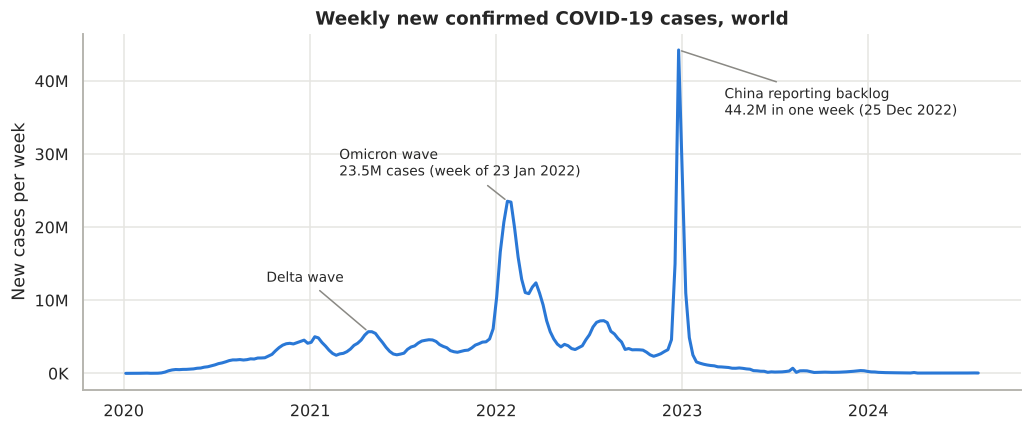

Highest week: 2022-12-25 44,236,227 cases, of which China 40,475,477
Omicron peak week: 2022-01-23 23,541,614 cases


In [11]:
weekly = df.set_index("date").groupby(pd.Grouper(freq="W"))[["new_cases", "new_deaths"]].sum()
weekly = weekly[weekly.index <= df["date"].max()]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(weekly.index, weekly["new_cases"], color=BLUE, lw=2)
ax.yaxis.set_major_formatter(millions)
ax.set_title("Weekly new confirmed COVID-19 cases, world")
ax.set_ylabel("New cases per week"); ax.set_xlabel("")
peak = weekly["new_cases"].idxmax()
om = weekly.loc["2022-01":"2022-02", "new_cases"]; op = om.idxmax()
ax.annotate(f"Omicron wave\n{om.max()/1e6:,.1f}M cases (week of {op:%d %b %Y})",
            xy=(op, om.max()), xytext=(op - pd.Timedelta(days=330), om.max()*1.15),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
ax.annotate(f"China reporting backlog\n{weekly['new_cases'].max()/1e6:,.1f}M in one week ({peak:%d %b %Y})",
            xy=(peak, weekly["new_cases"].max()), xytext=(peak + pd.Timedelta(days=90), weekly["new_cases"].max()*0.8),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
d = weekly.loc["2021-03":"2021-07", "new_cases"]; dp = d.idxmax()
ax.annotate("Delta wave", xy=(dp, d.max()), xytext=(dp - pd.Timedelta(days=200), d.max()*2.2),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
save(fig, "fig01_weekly_cases.png")
china = df[(df["country"] == "China")].set_index("date")["new_cases"].resample("W").sum()
print("Highest week:", peak.date(), f"{weekly['new_cases'].max():,.0f} cases, of which China {china.loc[peak]:,.0f}")
print("Omicron peak week:", op.date(), f"{om.max():,.0f} cases")

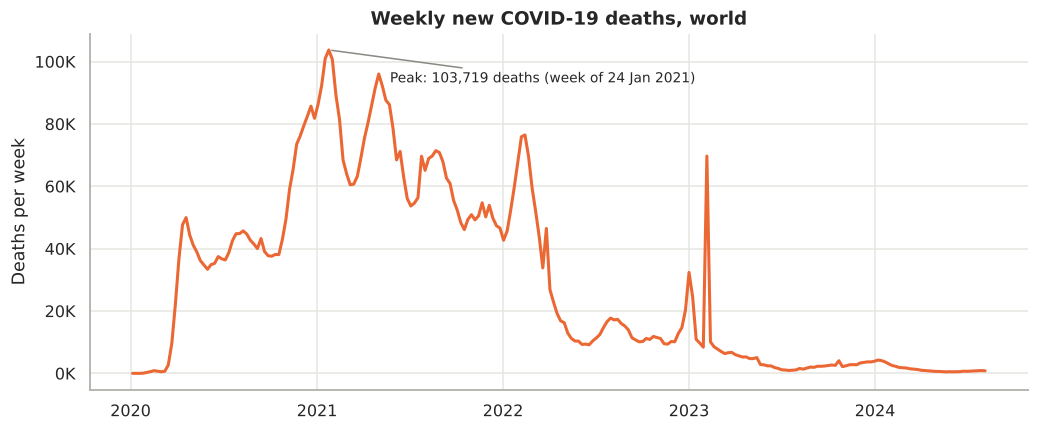

,new_cases,new_deaths,cfr_pct
date,,,
2020,"80,317,671.00","1,897,584.00",2.36
2021,"200,298,480.00","3,549,359.00",1.77
2022,"424,017,377.00","1,249,137.00",0.29
2023,"69,238,166.00","322,712.00",0.47
2024,"2,063,363.00","42,302.00",2.05


In [12]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(weekly.index, weekly["new_deaths"], color=ORANGE, lw=2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K"))
ax.set_title("Weekly new COVID-19 deaths, world")
ax.set_ylabel("Deaths per week"); ax.set_xlabel("")
pk = weekly["new_deaths"].idxmax()
ax.annotate(f"Peak: {weekly['new_deaths'].max():,.0f} deaths (week of {pk:%d %b %Y})",
            xy=(pk, weekly["new_deaths"].max()), xytext=(pk + pd.Timedelta(days=120), weekly["new_deaths"].max()*0.9),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
save(fig, "fig02_weekly_deaths.png")
yearly = df.groupby(df["date"].dt.year)[["new_cases", "new_deaths"]].sum()
yearly["cfr_pct"] = yearly["new_deaths"] / yearly["new_cases"] * 100
yearly

The largest sustained wave of cases was Omicron in January 2022. The single highest week (late December 2022) is a reporting artefact: China reported about 40 million cases at once after ending its zero-COVID policy, and this row is caught by the spike rule in Section 10. Deaths peaked much earlier, in January 2021 and during the Delta period; the short spike in deaths in early 2023 is again China's backlog. The case fatality rate fell from 2.4% in 2020 to under 0.5% in 2022-23: more testing found milder cases, treatment improved, and vaccines reduced severe illness. The 2024 figure is unreliable because very few cases were still being tested and reported.

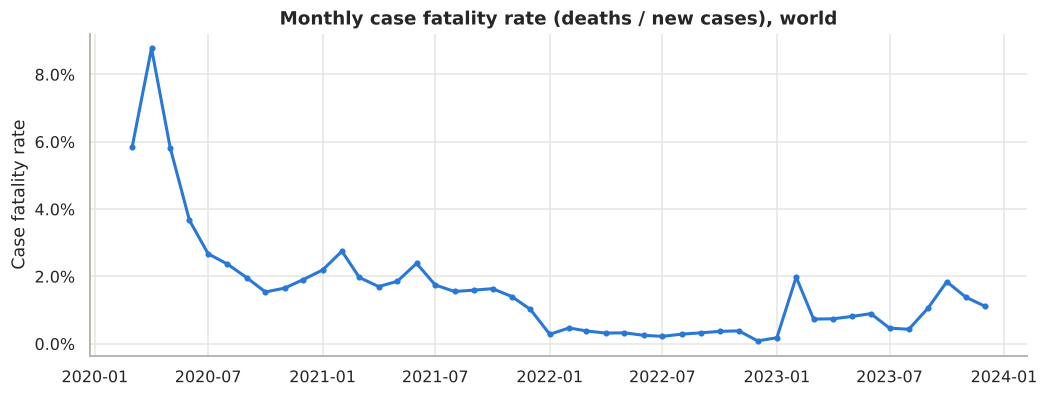

In [13]:
monthly = df.set_index("date").groupby(pd.Grouper(freq="MS"))[["new_cases", "new_deaths"]].sum()
monthly = monthly[(monthly.index >= "2020-03-01") & (monthly.index < "2024-01-01")]  # 2024 reporting too sparse
monthly["cfr_pct"] = monthly["new_deaths"] / monthly["new_cases"] * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(monthly.index, monthly["cfr_pct"], color=BLUE, lw=2, marker="o", ms=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_title("Monthly case fatality rate (deaths / new cases), world")
ax.set_ylabel("Case fatality rate"); ax.set_xlabel("")
save(fig, "fig03_cfr_trend.png")

## 6. Country and continent comparison

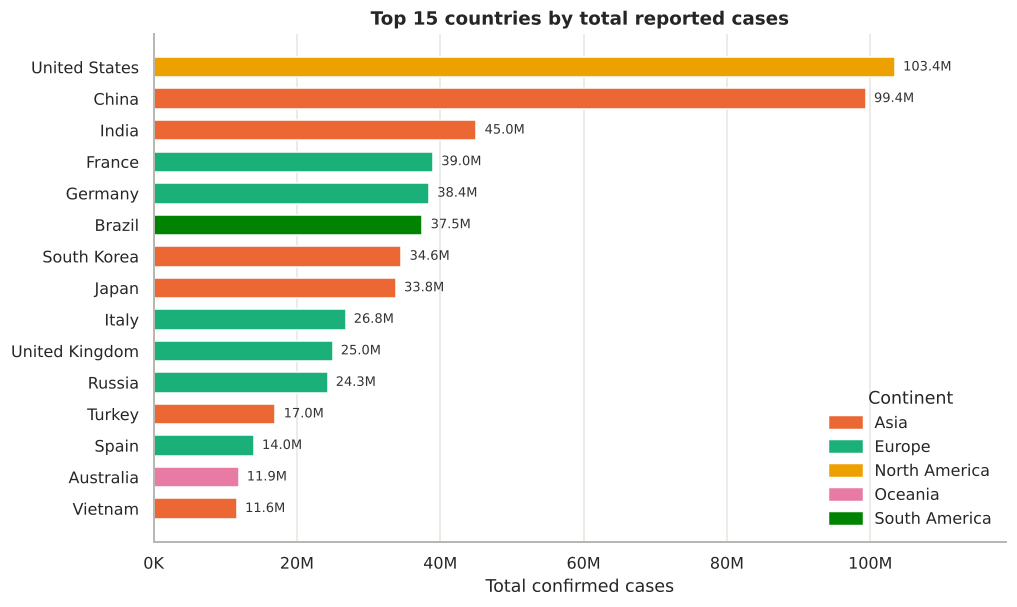

In [14]:
top = latest.nlargest(15, "confirmed").sort_values("confirmed")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["country"], top["confirmed"], color=[CONTINENT_COLORS[c] for c in top["continent"]], height=0.65)
ax.xaxis.set_major_formatter(millions)
for y, v in enumerate(top["confirmed"]):
    ax.text(v, y, f"  {v/1e6:,.1f}M", va="center", fontsize=8.5, color="#333")
ax.set_title("Top 15 countries by total reported cases")
ax.set_xlabel("Total confirmed cases"); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=CONTINENT_COLORS[c]) for c in CONTINENT_COLORS if c in set(top["continent"])]
ax.legend(handles, [c for c in CONTINENT_COLORS if c in set(top["continent"])], loc="lower right", frameon=False, title="Continent")
ax.set_xlim(0, top["confirmed"].max() * 1.15)
save(fig, "fig04_top15_cases.png")

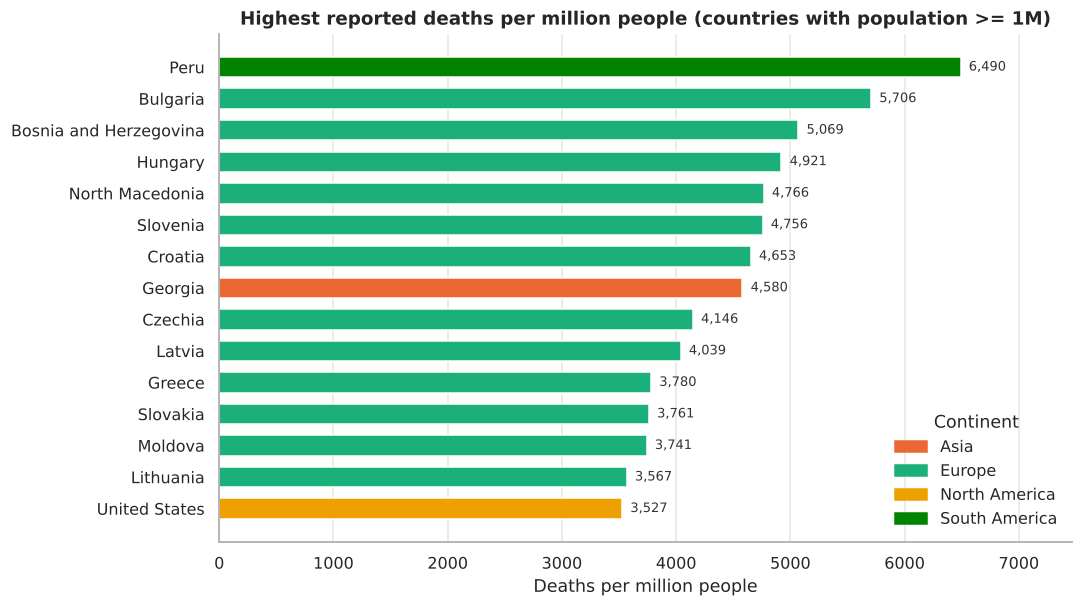

In [15]:
top_dpm = big.nlargest(15, "deaths_per_million").sort_values("deaths_per_million")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_dpm["country"], top_dpm["deaths_per_million"],
        color=[CONTINENT_COLORS[c] for c in top_dpm["continent"]], height=0.65)
for y, v in enumerate(top_dpm["deaths_per_million"]):
    ax.text(v, y, f"  {v:,.0f}", va="center", fontsize=8.5, color="#333")
ax.set_title("Highest reported deaths per million people (countries with population >= 1M)")
ax.set_xlabel("Deaths per million people"); ax.grid(axis="y", visible=False)
present = [c for c in CONTINENT_COLORS if c in set(top_dpm["continent"])]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=CONTINENT_COLORS[c]) for c in present], present,
          loc="lower right", frameon=False, title="Continent")
ax.set_xlim(0, top_dpm["deaths_per_million"].max() * 1.15)
save(fig, "fig05_top15_deaths_per_million.png")

Total counts favour large countries (USA, China, India). Per-million rates give a fairer comparison of the burden: by this measure the highest reported death rates are in Peru and in Eastern and Central Europe.

In [16]:
cont = latest.groupby("continent").agg(countries=("country", "count"), population=("population", "sum"),
                                       confirmed=("confirmed", "sum"), deaths=("deaths", "sum"),
                                       vaccinated=("vaccinated", "sum"))
cont["cases_per_million"] = cont["confirmed"] / cont["population"] * 1e6
cont["deaths_per_million"] = cont["deaths"] / cont["population"] * 1e6
cont["cfr_pct"] = cont["deaths"] / cont["confirmed"] * 100
cont["vaccinated_pct"] = cont["vaccinated"] / cont["population"] * 100
cont.sort_values("deaths_per_million", ascending=False)

,countries,population,confirmed,deaths,vaccinated,cases_per_million,deaths_per_million,cfr_pct,vaccinated_pct
continent,,,,,,,,,
South America,14,436816679,68809418,1354187,"375,459,127.00","157,524.70","3,100.13",1.97,85.95
Europe,51,747411270,252916868,2102483,"523,772,600.00","338,390.49","2,813.02",0.83,70.08
North America,41,600323657,124492666,1671178,"458,563,506.00","207,375.91","2,783.80",1.34,76.39
Oceania,24,45038907,15003352,32918,"28,960,501.00","333,119.81",730.88,0.22,64.30
Asia,47,4689377951,301499099,1637249,"3,658,751,332.00","64,294.05",349.14,0.54,78.02
Africa,57,1426160609,13145380,259117,"555,027,330.00","9,217.32",181.69,1.97,38.92


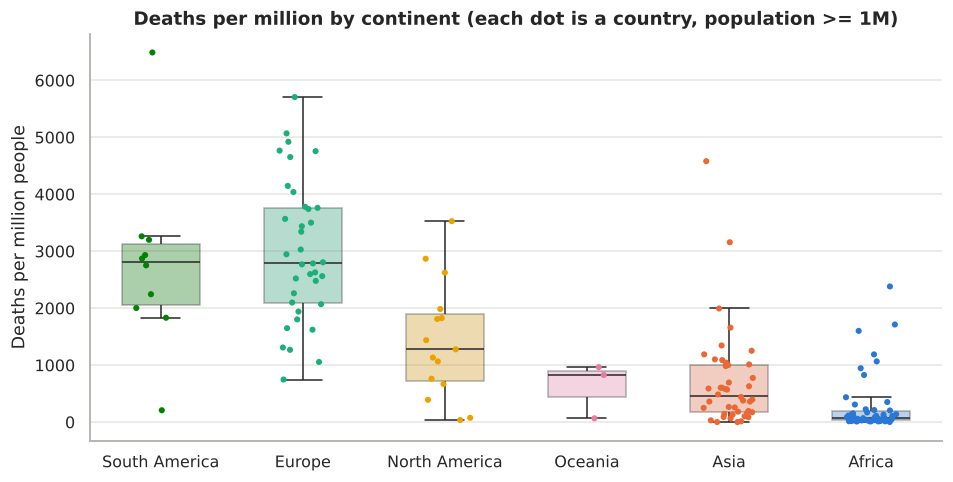

In [17]:
order = big.groupby("continent")["deaths_per_million"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=big, x="continent", y="deaths_per_million", order=order, palette=CONTINENT_COLORS,
            width=0.55, fliersize=0, boxprops=dict(alpha=0.35), ax=ax)
sns.stripplot(data=big, x="continent", y="deaths_per_million", order=order, palette=CONTINENT_COLORS,
              size=4, jitter=0.18, ax=ax)
ax.set_title("Deaths per million by continent (each dot is a country, population >= 1M)")
ax.set_xlabel(""); ax.set_ylabel("Deaths per million people")
save(fig, "fig06_continent_box.png")

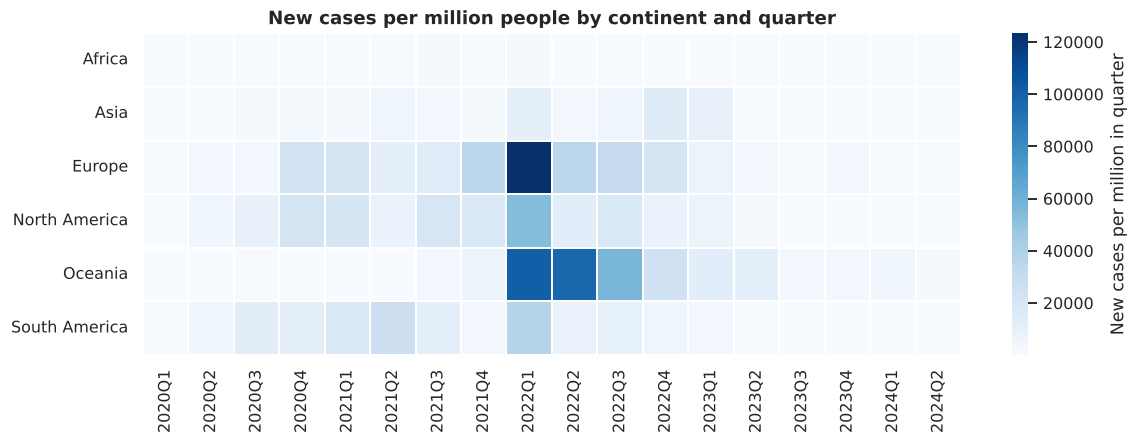

In [18]:
heat = (df.assign(month=df["date"].dt.to_period("Q").astype(str))
          .groupby(["continent", "month"]).agg(cases=("new_cases", "sum")).reset_index())
pop_c = latest.groupby("continent")["population"].sum()
heat["cases_per_million"] = heat["cases"] / heat["continent"].map(pop_c) * 1e6
pivot = heat.pivot(index="continent", columns="month", values="cases_per_million")
pivot = pivot.loc[:, (pivot.columns >= "2020Q1") & (pivot.columns <= "2024Q2")]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pivot, cmap="Blues", linewidths=1, linecolor="white", ax=ax,
            cbar_kws={"label": "New cases per million in quarter"}, annot=False)
ax.set_title("New cases per million people by continent and quarter")
ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "fig07_continent_quarter_heatmap.png")

## 7. Vaccination analysis

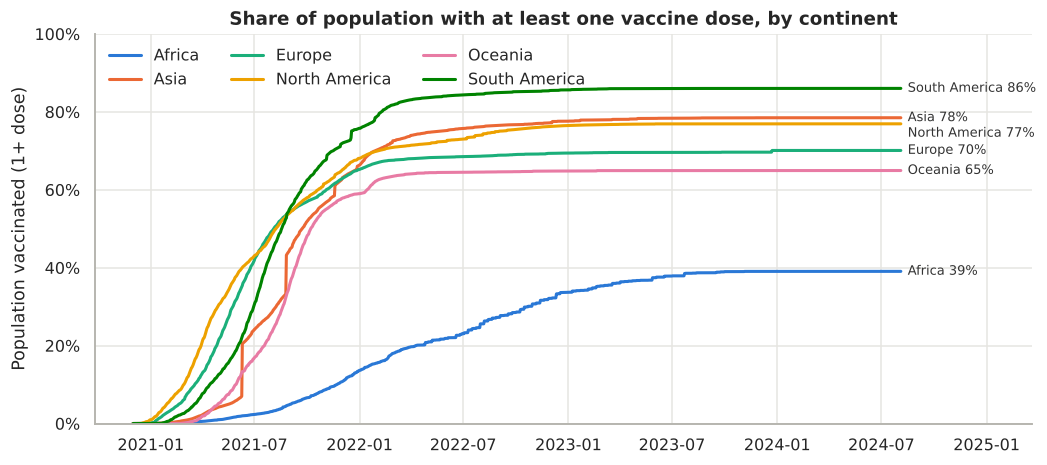

,continent,coverage_pct
10043,South America,86.01
10039,Asia,78.48
10041,North America,76.92
10040,Europe,70.08
10042,Oceania,64.93
10038,Africa,39.05


In [19]:
vax = df.dropna(subset=["vaccinated"]).groupby(["date", "continent"]).agg(vaccinated=("vaccinated", "sum")).reset_index()
pop_rep = df.dropna(subset=["vaccinated"]).drop_duplicates("country").groupby("continent")["population"].sum()
vax["coverage_pct"] = vax["vaccinated"] / vax["continent"].map(pop_rep) * 100
vax = vax[vax["date"] >= "2020-12-01"]

fig, ax = plt.subplots(figsize=(11, 4.6))
ends = {}
for c, col in CONTINENT_COLORS.items():
    s = vax[vax["continent"] == c]
    ax.plot(s["date"], s["coverage_pct"], color=col, lw=2, label=c)
    ends[c] = s["coverage_pct"].iloc[-1]
# direct labels at the line ends, nudged apart so they do not overlap
prev = None
for c, y in sorted(ends.items(), key=lambda kv: -kv[1]):
    y_lab = y if prev is None else min(y, prev - 4)
    ax.text(vax["date"].max() + pd.Timedelta(days=12), y_lab, f"{c} {y:.0f}%", color="#333", fontsize=8.5, va="center")
    prev = y_lab
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 100); ax.set_xlim(right=vax["date"].max() + pd.Timedelta(days=230))
ax.set_title("Share of population with at least one vaccine dose, by continent")
ax.set_ylabel("Population vaccinated (1+ dose)"); ax.set_xlabel("")
ax.legend(frameon=False, ncol=3, loc="upper left")
save(fig, "fig08_vaccination_by_continent.png")
vax[vax["date"] == vax["date"].max()][["continent", "coverage_pct"]].sort_values("coverage_pct", ascending=False)

Vaccination rolled out from December 2020. Coverage rose fastest in North America and Europe at first, and South America reached the highest level (86%). Africa lagged far behind (39%), reflecting unequal access to vaccine supplies. The sudden step in Asia's line in mid-2021 is when China began reporting the number of people vaccinated, not a single-day event.

Countries: 154 | Spearman rho = 0.62, p = 8.58e-18


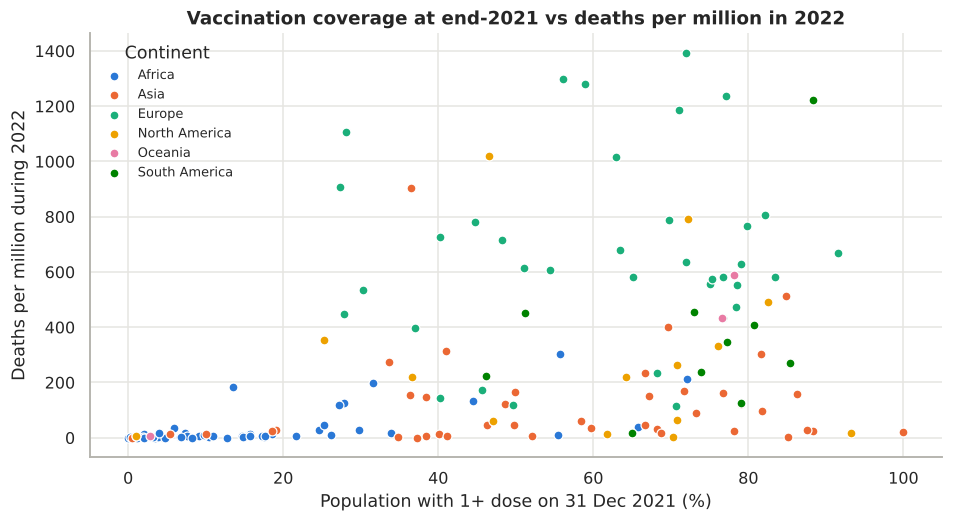

In [20]:
# Does higher vaccination coverage by end-2021 go with fewer deaths in 2022?
end21 = df[df["date"] == "2021-12-31"].set_index("country")
d22 = (df[df["date"].dt.year == 2022].groupby("country")["new_deaths"].sum())
sc = pd.DataFrame({"vax_end_2021": end21["vax_coverage_pct"], "pop": end21["population"],
                   "continent": end21["continent"], "deaths_2022": d22}).dropna()
sc = sc[sc["pop"] >= 1_000_000]
sc["deaths_pm_2022"] = sc["deaths_2022"] / sc["pop"] * 1e6
rho, p = stats.spearmanr(sc["vax_end_2021"], sc["deaths_pm_2022"])
print(f"Countries: {len(sc)} | Spearman rho = {rho:.2f}, p = {p:.3g}")

fig, ax = plt.subplots(figsize=(10, 5))
for c, col in CONTINENT_COLORS.items():
    s = sc[sc["continent"] == c]
    ax.scatter(s["vax_end_2021"], s["deaths_pm_2022"], s=34, color=col, label=c, edgecolor="white", lw=0.8)
ax.set_title("Vaccination coverage at end-2021 vs deaths per million in 2022")
ax.set_xlabel("Population with 1+ dose on 31 Dec 2021 (%)"); ax.set_ylabel("Deaths per million during 2022")
ax.legend(frameon=False, fontsize=8.5, title="Continent")
save(fig, "fig09_vax_vs_deaths_scatter.png")

The relationship is **positive** (Spearman rho about 0.6): countries that were more vaccinated at the end of 2021 *reported* more deaths per million in 2022. This seems surprising. It is a good example of *confounding*: countries with high vaccination are mostly richer countries with older populations and much more testing and death reporting, so they record more COVID deaths. A simple country-level correlation cannot show the effect of vaccines; clinical trials and studies that compare vaccinated and unvaccinated individuals are needed for that. This finding is reported as an association only.

## 8. Case study: India

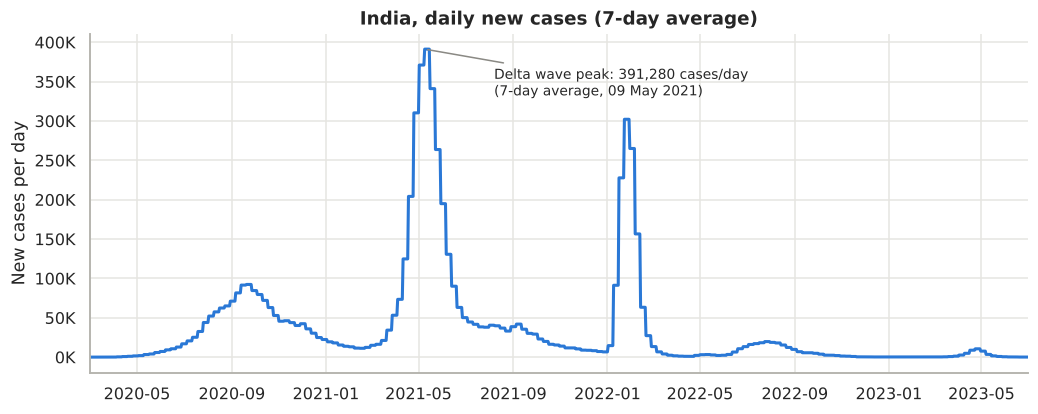

India: 45,041,748 cases | 533,623 deaths | CFR 1.18% | 377 deaths per million | 72.5% vaccinated (1+ dose)


In [21]:
india = df[df["country"] == "India"].set_index("date")
india_7d = india["new_cases"].rolling(7).mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(india_7d.index, india_7d, color=BLUE, lw=2)
ax.yaxis.set_major_formatter(millions)
pk = india_7d.loc["2021"].idxmax()
ax.annotate(f"Delta wave peak: {india_7d.max():,.0f} cases/day\n(7-day average, {pk:%d %b %Y})",
            xy=(pk, india_7d.loc[pk]), xytext=(pk + pd.Timedelta(days=90), india_7d.loc[pk]*0.85),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
ax.set_title("India, daily new cases (7-day average)")
ax.set_ylabel("New cases per day"); ax.set_xlabel("")
ax.set_xlim(pd.Timestamp("2020-03-01"), pd.Timestamp("2023-06-30"))
save(fig, "fig10_india_daily_cases.png")
il = latest[latest["country"] == "India"].iloc[0]
print(f"India: {il['confirmed']:,} cases | {il['deaths']:,} deaths | CFR {il['cfr_pct']:.2f}% | "
      f"{il['deaths_per_million']:,.0f} deaths per million | {il['vax_coverage_pct']:.1f}% vaccinated (1+ dose)")

## 9. Correlation analysis

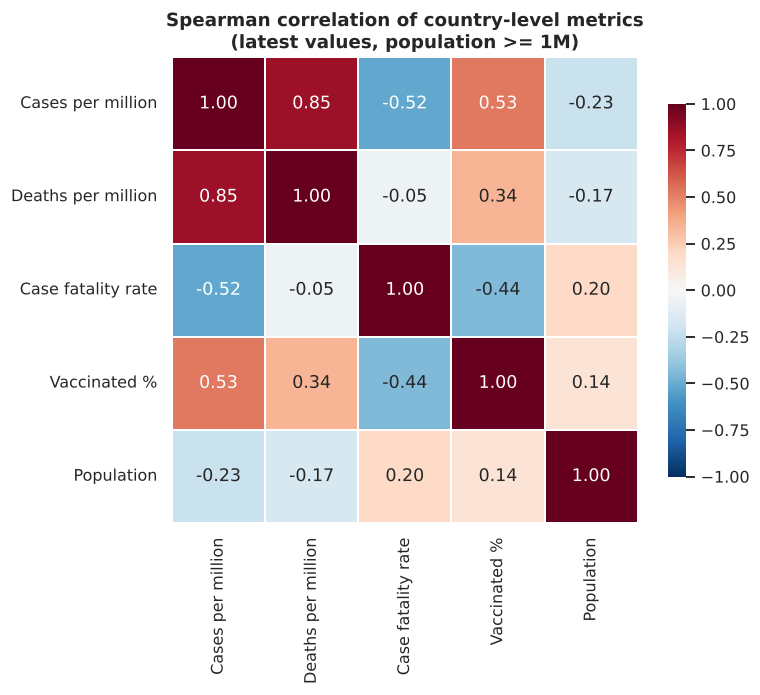

In [22]:
corr_cols = {"cases_per_million": "Cases per million", "deaths_per_million": "Deaths per million",
             "cfr_pct": "Case fatality rate", "vax_coverage_pct": "Vaccinated %", "population": "Population"}
cm = big[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation of country-level metrics\n(latest values, population >= 1M)")
save(fig, "fig11_correlation_heatmap.png")

Cases per million is strongly correlated with deaths per million (0.85) and moderately with vaccination coverage (0.53): all three tend to be higher in countries with stronger testing and reporting systems. Case fatality rate is *negatively* correlated with cases per million (-0.52): countries that tested widely found many mild cases, which lowers the ratio. Population size has little relationship with any rate.

## 10. Data-quality flags (anomalies)

In [23]:
anom = pd.read_csv(DATA / "anomalies.csv")
flag_rows = anom[["date", "country"]].drop_duplicates().shape[0]
print(f"Flagged rows: {flag_rows:,} of {len(df):,} ({flag_rows/len(df):.2%})")
anom.groupby("issue").agg(rows=("country", "size"), countries=("country", "nunique")).sort_values("rows", ascending=False)

Flagged rows: 5,509 of 391,716 (1.41%)


,rows,countries
issue,,
vaccinated_exceed_population,4861,6
case_spike_over_5x_4week_avg,403,162
deaths_exceed_confirmed,217,5
confirmed_decreased,19,19
deaths_decreased,12,12


| Rule | Meaning | Treatment |
|---|---|---|
| vaccinated_exceed_population | More people vaccinated than the official population (e.g. UAE, Qatar, Gibraltar vaccinate non-resident workers and visitors) | Kept; coverage capped at 100% in charts |
| case_spike_over_5x_4week_avg | A weekly total more than 5 times the average of the previous 4 weeks (and above 1,000), e.g. China's December 2022 backlog, or the first fast weeks of a new wave | Kept, labelled on the weekly cases chart (Section 5) |
| deaths_exceed_confirmed | Early-2020 reporting mismatches (e.g. France, Germany) | Kept and flagged |
| confirmed_decreased / deaths_decreased | Cumulative totals revised downwards | Daily values set to 0 for those days |

Rows were **flagged, not deleted**, so the cleaned dataset stays faithful to the official source.

## 11. Key findings

In [24]:
f = {
    "Total reported cases": f"{latest['confirmed'].sum()/1e6:,.1f} million",
    "Total reported deaths": f"{latest['deaths'].sum()/1e6:,.2f} million",
    "Overall case fatality rate": f"{latest['deaths'].sum()/latest['confirmed'].sum():.2%}",
    "Omicron peak week (cases)": f"{op:%d %b %Y}",
    "Peak week for deaths": f"{weekly['new_deaths'].idxmax():%d %b %Y}",
    "CFR in 2020 vs 2023": f"{yearly.loc[2020, 'cfr_pct']:.2f}% vs {yearly.loc[2023, 'cfr_pct']:.2f}%",
    "Most cases (total)": latest.nlargest(1, 'confirmed')['country'].iloc[0],
    "Highest deaths per million (pop >= 1M)": big.nlargest(1, 'deaths_per_million')['country'].iloc[0],
    "World population vaccinated (1+ dose)": f"{latest['vaccinated'].sum()/world_pop:.1%}",
    "Rows flagged by quality rules": f"{flag_rows/len(df):.2%}",
}
pd.Series(f, name="Value").to_frame()

,Value
Total reported cases,775.9 million
Total reported deaths,7.06 million
Overall case fatality rate,0.91%
Omicron peak week (cases),23 Jan 2022
Peak week for deaths,24 Jan 2021
CFR in 2020 vs 2023,2.36% vs 0.47%
Most cases (total),United States
Highest deaths per million (pop >= 1M),Peru
World population vaccinated (1+ dose),70.5%
Rows flagged by quality rules,1.41%


1. **Scale:** more than 775 million cases and about 7 million deaths were reported worldwide between January 2020 and August 2024.
2. **Waves:** the biggest wave of cases was Omicron (January 2022), while deaths peaked earlier, in January 2021 and during the Delta wave. The single highest week (December 2022) is a China reporting backlog, which the quality rules flag.
3. **Severity fell:** the case fatality rate fell from 2.36% in 2020 to 0.29% in 2022 and 0.47% in 2023.
4. **Fair comparison needs per-capita figures:** totals rank the USA, China and India first, but per-million rates show the heaviest reported death burden in Peru and Eastern and Central Europe.
5. **Unequal vaccination:** Africa's vaccination coverage stayed far behind other continents.
6. **Correlation is not causation:** the country-level association between vaccination and deaths is distorted by reporting quality and population age.

*Interactive dashboard:* run `python src/build_dashboard.py` and open `dashboard/covid_dashboard.html`.